<a href="https://colab.research.google.com/github/ErrPeppe/OhnomiTools/blob/main/notebooks/04_expression_epigenetics_robustness.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fase 4 — Dinamica di Espressione Multi-Contesto, Subfunzionalizzazione e Profilo Epigenetico/Multi-Omico

## Introduzione Biologica, Fisica e Metodi Matematici

### 1. Perché Spostarsi sull'Espressione e sui Layer Multi-Omici dopo la Fase 3
La Fase 3 ha stabilito un risultato chiave: a differenza degli ohno-miRNA umani (Agasso et al., 2025), la ritenzione evolutiva delle coppie di **ohno-lncRNA intragenici** (dimostrata nella Fase 2 con $\text{OR}_{\text{adj}}$ fino a $1{,}41$) **non è sostenuta da una conservazione sistematica di siti di legame ai miRNA (*ceRNA*)**, mentre emerge un netto gradiente topologico a favore dei **lincRNA intergenici ancestrali** (`17. Euteleostomi`) su entrambi i layer di interazione (miRNA e RBP).

In questa fase verifichiamo se l'impronta delle 1R/2R-WGD si manifesta invece sul piano della **dinamica di espressione** e della **regolazione epigenetica**, replicando ed estendendo le analisi di Agasso et al. (2025, Fig. 5D e Fig. 7) e l'ipotesi di Makino & McLysaght (2010) sul legame tra ohnologhi dosaggio-sensibili e patologie umane:
1. **Robustezza e ampiezza di espressione:** gli ohno-lncRNA (Via 1, Via 2 e Via 3) sono espressi in modo più robusto, ubiquitario e con maggiore rilevanza nello **sviluppo embrionale e degli organi** rispetto ai controlli SSD antichi e ai lncRNA recenti (`12. Eutheria`, `1. Homo`)?
2. **Co-espressione conservata vs subfunzionalizzazione nelle coppie duplicate:** dopo una WGD, le due copie mantengono un profilo di espressione più simile tra loro oppure divergono in compartimenti diversi rispetto alle coppie SSD?
3. **Firma epigenetica e controllo del potenziale codificante nascosto:** integrazione della metilazione differenziale su 16 patologie (`lncbook_methylation.parquet`) e del catalogo sperimentale di micropeptidi (`lncbook_sprotein.parquet`, Ribo-seq e spettrometria di massa) per caratterizzare la suscettibilità epigenetica e separare i veri RNA non codificanti da eventuali trascritti bifunzionali.

### 2. Formulazione Matematica delle Metriche (Codifica Ordinale LncBook v2.0)
Il dataset `expression_LncBook2.0.csv.gz` sintetizza i profili trascrittomici di LncBook v2.0 in una matrice meta-categoriale ordinale su $M = 9$ contesti biologici (*Normal Tissue/Cell Line*, *Organ Development*, *Preimplantation Embryo*, *Cell Differentiation*, *Subcellular Localization*, *Exosome*, *Cancer Cell Line*, *Virus Infection*, *Circadian Rhythm*), codificata numericamente come:
$$e_{g,c} \in \{0, 1, 2, 3\} \quad (\text{NE} = 0,\; \text{LC} = 1,\; \text{MC} = 2,\; \text{HC} = 3)$$
Per ogni gene $g$ definiamo lo score medio $\bar{e}_g = \frac{1}{M}\sum_{c=1}^M e_{g,c}$ e l'ampiezza ad alta/media capacità $B_g = \sum_{c=1}^M \mathbb{I}(e_{g,c} \ge 2)$. Per ogni coppia duplicata $(g_1, g_2)$ calcoliamo:
* **Distanza Coseno** (Agasso et al., 2025, Fig. 5D — sensibile alla forma relativa del profilo, definita quando $\|\mathbf{e}_1\|, \|\mathbf{e}_2\| > 0$):
  $$d_{\cos}(\mathbf{e}_1, \mathbf{e}_2) = 1 - \frac{\mathbf{e}_1 \cdot \mathbf{e}_2}{\|\mathbf{e}_1\|_2\,\|\mathbf{e}_2\|_2} \in [0, 1]$$
* **Distanza di Manhattan Normalizzata** (sensibile sia alla forma sia all'ampiezza assoluta, definita su tutte le coppie):
  $$d_{L_1}(\mathbf{e}_1, \mathbf{e}_2) = \frac{1}{3M}\sum_{c=1}^{M} |e_{1,c} - e_{2,c}| \in [0, 1]$$
* **Asimmetria di Espressione:** $\tilde{\Delta}E = \frac{|S_1 - S_2|}{S_1 + S_2}$, con $S_i = \sum_c e_{i,c}$.

I confronti tra coorti e coppie vengono valutati tramite **test U di Mann–Whitney**, **test di Kolmogorov–Smirnov** e **test esatto di Fisher** (per proporzioni binarie di `Featured Expression`, metilazione differenziale e micropeptidi `SmProt`).

## 1. Setup Ambiente e Costruzione della Tabella Multi-Omica (`Silver`)
Installazione dell'ultima versione di `OhnomiTools` (con `expression.py`) e costruzione della tabella unificata per gene che integra espressione su 9 contesti, metilazione differenziale in 16 patologie e micropeptidi `SmProt`.

In [ ]:
!pip install -q --no-cache-dir git+https://github.com/ErrPeppe/OhnomiTools.git
from ohnomitools import setup_colab
from ohnomitools.expression import MultiOmicsExpressionAnalyzer

PATHS = setup_colab(show_status=False)
mo_analyzer = MultiOmicsExpressionAnalyzer(paths=PATHS)
df_mo = mo_analyzer.build_gene_multiomics_table(force_rebuild=True)

print(f"Tabella multi-omica pronta: {len(df_mo):,} geni lncRNA x {len(df_mo.columns)} colonne")
display(df_mo.head(3))

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Tabella multi-omica pronta: 95,238 geni lncRNA x 33 colonne


lncrna_gene_id,chr,strand,lnc_length_bp,n_isoforms,expr_symbol,is_featured_expr,global_expr_capacity,expr__Normal Tissue/Cell Line,expr__Organ Development,expr__Preimplantation Embryo,expr__Cell Differentiation,expr__Subcellular Localization,expr__Exosome,expr__Cancer Cell Line,expr__Virus Infection,expr__Circadian Rhythm,expr_sum_score,n_ctx_expressed,n_ctx_hc_mc,n_ctx_hc,in_expr_db,expr_mean_score,has_diff_methylation,has_promoter_meth,has_body_meth,n_meth_hyper_events,n_meth_hypo_events,n_meth_total_events,has_sprotein,n_sproteins,has_sprotein_ms,has_sprotein_riboseq
str,str,str,i64,u32,str,bool,i8,i8,i8,i8,i8,i8,i8,i8,i8,i8,i8,i8,i8,i8,bool,f64,bool,bool,bool,i64,i64,i64,bool,u32,bool,bool
"""HSALNG0106946""","""chr15""","""-""",1221,1,"""-""",false,3,0,1,2,0,0,3,0,0,0,6,3,2,1,true,0.666667,true,true,false,1,0,1,false,0,false,false
"""HSALNG0123360""","""chr19""","""-""",2770,2,"""-""",false,3,2,0,2,2,0,3,2,2,0,13,6,6,1,true,1.444444,false,false,false,0,0,0,false,0,false,false
"""HSALNG0107109""","""chr15""","""+""",8238,8,"""-""",false,3,1,1,0,1,0,3,0,0,0,6,4,1,1,true,0.666667,false,false,false,0,0,0,false,0,false,false


## 2. Profilo di Espressione, Metilazione e Micropeptidi sulle 3 Vie
Confronto sistematico di tutte le coorti (Via 1, Via 2, Via 3 e controlli di età `12. Eutheria`, `1. Homo`) su capacità di espressione, `Featured Expression`, deregolazione epigenetica e micropeptidi `SmProt`, con test di Mann–Whitney e Fisher esatto.

In [ ]:
import polars as pl

cohort_res = mo_analyzer.analyze_expression_and_multiomics_cohorts(df_mo=df_mo)

with pl.Config(tbl_rows=15, tbl_cols=15, fmt_str_lengths=38):
    print("=== RIEPILOGO MULTI-OMICO SULLE 3 VIE ===")
    print(cohort_res["summary"])
    print("\n=== TEST STATISTICI (MANN-WHITNEY & FISHER ESATTO) ===")
    print(cohort_res["tests"])

=== RIEPILOGO MULTI-OMICO SULLE 3 VIE ===
shape: (10, 13)
┌─────┬─────┬─────┬────────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┐
│ Via ┆ Coo ┆ N_g ┆ In_Exp ┆ Featu ┆ Globa ┆ Mean_ ┆ Media ┆ Mean_ ┆ Diff_ ┆ Promo ┆ SmPro ┆ SmPro │
│ --- ┆ rte ┆ eni ┆ r_DB_p ┆ red_E ┆ l_HC_ ┆ Score ┆ n_Ctx ┆ Ctx_H ┆ Meth_ ┆ ter_M ┆ t_pct ┆ t_MS_ │
│ str ┆ --- ┆ --- ┆ ct     ┆ xpr_p ┆ pct   ┆ _0_3  ┆ _Expr ┆ C_MC  ┆ pct   ┆ eth_p ┆ ---   ┆ pct   │
│     ┆ str ┆ i64 ┆ ---    ┆ ct    ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ct    ┆ f64   ┆ ---   │
│     ┆     ┆     ┆ f64    ┆ ---   ┆ f64   ┆ f64   ┆ f64   ┆ f64   ┆ f64   ┆ ---   ┆       ┆ f64   │
│     ┆     ┆     ┆        ┆ f64   ┆       ┆       ┆       ┆       ┆       ┆ f64   ┆       ┆       │
╞═════╪═════╪═════╪════════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╪═══════╡
│ Via ┆ WGD ┆ 104 ┆ 100.0  ┆ 30.44 ┆ 41.47 ┆ 0.812 ┆ 4.0   ┆ 2.822 ┆ 19.97 ┆ 11.94 ┆ 5.66  ┆ 0.18  │
│ 1   ┆ _in ┆ 80  ┆        ┆     

## 3. Profilo Dettagliato di Espressione (`HC+MC`) nei 9 Contesti Biologici
Scomposizione della frazione di lncRNA ad alta/media capacità espressiva (`HC` o `MC`) in ciascuno dei 9 contesti biologici di LncBook v2.0, con particolare attenzione ai contesti legati allo sviluppo dei vertebrati (`Organ Development`, `Preimplantation Embryo`, `Cell Differentiation`).

In [ ]:
with pl.Config(tbl_rows=15, tbl_cols=12, fmt_str_lengths=35):
    print("=== PERCENTUALE DI GENI HC+MC PER CONTESTO BIOLOGICO ===")
    print(cohort_res["contexts"])

=== PERCENTUALE DI GENI HC+MC PER CONTESTO BIOLOGICO ===
shape: (10, 11)
┌────────┬────────┬────────┬────────┬────────┬────────┬────────┬────────┬────────┬────────┬────────┐
│ Via    ┆ Coorte ┆ Normal ┆ Organ  ┆ Preimp ┆ Cell   ┆ Subcel ┆ Exosom ┆ Cancer ┆ Virus  ┆ Circad │
│ ---    ┆ ---    ┆ Tissue ┆ Develo ┆ lantat ┆ Differ ┆ lular  ┆ e_HC_M ┆ Cell   ┆ Infect ┆ ian    │
│ str    ┆ str    ┆ /Cell  ┆ pment_ ┆ ion    ┆ entiat ┆ Locali ┆ C_pct  ┆ Line_H ┆ ion_HC ┆ Rhythm │
│        ┆        ┆ Line_H ┆ HC_MC_ ┆ Embryo ┆ ion_HC ┆ zation ┆ ---    ┆ C_MC_p ┆ _MC_pc ┆ _HC_MC │
│        ┆        ┆ C_MC_p ┆ pct    ┆ _HC_MC ┆ _MC_pc ┆ _HC_MC ┆ f64    ┆ ct     ┆ t      ┆ _pct   │
│        ┆        ┆ ct     ┆ ---    ┆ _pct   ┆ t      ┆ _pct   ┆        ┆ ---    ┆ ---    ┆ ---    │
│        ┆        ┆ ---    ┆ f64    ┆ ---    ┆ ---    ┆ ---    ┆        ┆ f64    ┆ f64    ┆ f64    │
│        ┆        ┆ f64    ┆        ┆ f64    ┆ f64    ┆ f64    ┆        ┆        ┆        ┆        │
╞════════╪════════

## 4. Co-espressione vs Subfunzionalizzazione nelle Coppie Duplicate (Via 1 e Via 2)
Calcolo della **Cosine Distance ($1 - \cos$)**, della **Manhattan normalizzata ($d_{L_1}$)** e dell'**asimmetria di espressione** sulle coppie WGD vs SSD antiche nella Via 1 e nella Via 2, con test di Kolmogorov–Smirnov e Mann–Whitney U e stampa delle coppie WGD Via 2 più co-espresse e più divergenti.

In [ ]:
pair_res = mo_analyzer.analyze_pairwise_expression_divergence(df_mo=df_mo)

with pl.Config(tbl_rows=10, tbl_cols=12, fmt_str_lengths=35):
    print("=== DIVERGENZA DI ESPRESSIONE A COPPIE (RIEPILOGO) ===")
    print(pair_res["summary"])
    print("\n=== CONFRONTO WGD vs SSD ANTICHE (KS & MANN-WHITNEY) ===")
    print(pair_res["tests"])

tw2 = pair_res["pair_tables"]["via2_WGD"].filter(pl.col("both_expressed"))
print("\n=== TOP 8 COPPIE WGD VIA 2 PIÙ CO-ESPRESSE (bassa distanza, entrambi molto espressi) ===")
display(
    tw2.filter((pl.col("expr_sum_1") >= 15) & (pl.col("expr_sum_2") >= 15))
    .sort(["manhattan_norm", "cosine_distance"])
    .select([
        "gene_name_1", "gene_name_2", "lncrna_1", "lncrna_2",
        "lncrna_age_1", "lncrna_age_2", "expr_sum_1", "expr_sum_2",
        "cosine_distance", "manhattan_norm", "exact_ctx_match"
    ])
    .head(8)
)

print("\n=== TOP 8 COPPIE WGD VIA 2 PIÙ DIVERGENTI / SUBFUNZIONALIZZATE ===")
display(
    tw2.sort(["cosine_distance", "manhattan_norm"], descending=True)
    .select([
        "gene_name_1", "gene_name_2", "lncrna_1", "lncrna_2",
        "lncrna_age_1", "lncrna_age_2", "expr_sum_1", "expr_sum_2",
        "cosine_distance", "manhattan_norm", "expr_asymmetry"
    ])
    .head(8)
)

=== DIVERGENZA DI ESPRESSIONE A COPPIE (RIEPILOGO) ===
shape: (4, 10)
┌──────┬──────┬──────────┬──────────┬──────────┬──────────┬──────────┬─────────┬─────────┬─────────┐
│ Via  ┆ Tipo ┆ N_coppie ┆ Both_Exp ┆ CosDist_ ┆ CosDist_ ┆ Manhatta ┆ Manhatt ┆ Asimmet ┆ ExactMa │
│ ---  ┆ ---  ┆ _in_Expr ┆ ressed_p ┆ media    ┆ mediana  ┆ n_media  ┆ an_medi ┆ ria_med ┆ tch_med │
│ str  ┆ str  ┆ ---      ┆ ct       ┆ ---      ┆ ---      ┆ ---      ┆ ana     ┆ ia      ┆ ia      │
│      ┆      ┆ i64      ┆ ---      ┆ f64      ┆ f64      ┆ f64      ┆ ---     ┆ ---     ┆ ---     │
│      ┆      ┆          ┆ f64      ┆          ┆          ┆          ┆ f64     ┆ f64     ┆ f64     │
╞══════╪══════╪══════════╪══════════╪══════════╪══════════╪══════════╪═════════╪═════════╪═════════╡
│ via1 ┆ WGD  ┆ 19739    ┆ 85.6     ┆ 0.3314   ┆ 0.2929   ┆ 0.2427   ┆ 0.2222  ┆ 0.3957  ┆ 0.5413  │
│ via1 ┆ SSD  ┆ 220057   ┆ 83.32    ┆ 0.3517   ┆ 0.3118   ┆ 0.2616   ┆ 0.2222  ┆ 0.4161  ┆ 0.511   │
│ via2 ┆ WGD  ┆ 762  

gene_name_1,gene_name_2,lncrna_1,lncrna_2,lncrna_age_1,lncrna_age_2,expr_sum_1,expr_sum_2,cosine_distance,manhattan_norm,exact_ctx_match
str,str,str,str,str,str,i32,i32,f64,f64,f64
"""PDE6B""","""PDE6C""","""HSALNG0032163""","""HSALNG0079762""","""15. Amniota""","""16. Tetrapoda""",15,15,0.09489,0.14815,0.6667
"""STK24""","""STK25""","""HSALNG0098860""","""HSALNG0023689""","""17. Euteleostomi""","""15. Amniota""",15,18,0.10197,0.18519,0.5556
"""LGALS3""","""LGALS8""","""HSALNG0101450""","""HSALNG0011779""","""15. Amniota""","""15. Amniota""",17,17,0.08571,0.22222,0.3333
"""PDE6B""","""PDE6C""","""HSALNG0032161""","""HSALNG0079762""","""17. Euteleostomi""","""16. Tetrapoda""",15,15,0.22419,0.37037,0.1111



=== TOP 8 COPPIE WGD VIA 2 PIÙ DIVERGENTI / SUBFUNZIONALIZZATE ===


gene_name_1,gene_name_2,lncrna_1,lncrna_2,lncrna_age_1,lncrna_age_2,expr_sum_1,expr_sum_2,cosine_distance,manhattan_norm,expr_asymmetry
str,str,str,str,str,str,i32,i32,f64,f64,f64
"""SCN8A""","""SCN4A""","""HSALNG0091105""","""HSALNG0118053""","""16. Tetrapoda""","""16. Tetrapoda""",3,10,1.0,0.48148,0.53846
"""SCN8A""","""SCN4A""","""HSALNG0091106""","""HSALNG0118053""","""16. Tetrapoda""","""16. Tetrapoda""",2,10,1.0,0.44444,0.66667
"""MARK2""","""MARK1""","""HSALNG0084725""","""HSALNG0010741""","""15. Amniota""","""15. Amniota""",11,1,1.0,0.44444,0.83333
"""ACVR2B""","""ACVR2A""","""HSALNG0025232""","""HSALNG0019473""","""17. Euteleostomi""","""17. Euteleostomi""",2,9,1.0,0.40741,0.63636
"""TIMP3""","""TIMP2""","""HSALNG0135045""","""HSALNG0119073""","""15. Amniota""","""17. Euteleostomi""",4,7,1.0,0.40741,0.27273
"""CIRBP""","""ELAVL1""","""HSALNG0123000""","""HSALNG0123699""","""16. Tetrapoda""","""15. Amniota""",10,1,1.0,0.40741,0.81818
"""CFTR""","""ABCA5""","""HSALNG0060794""","""HSALNG0118420""","""16. Tetrapoda""","""17. Euteleostomi""",2,8,1.0,0.37037,0.6
"""WDFY3""","""WDFY4""","""HSALNG0035619""","""HSALNG0077856""","""17. Euteleostomi""","""15. Amniota""",5,5,1.0,0.37037,0.0


## 5. Visualizzazione Riassuntiva della Fase 4 (Export in `gold/`)
Esportazione della figura a 3 pannelli (`gold/phase4_expression_multiomics_summary.png` e `.pdf`) con il profilo sui 9 contesti biologici, la divergenza di espressione nelle coppie WGD vs SSD e il confronto multi-omico integrato sulle 3 Vie.

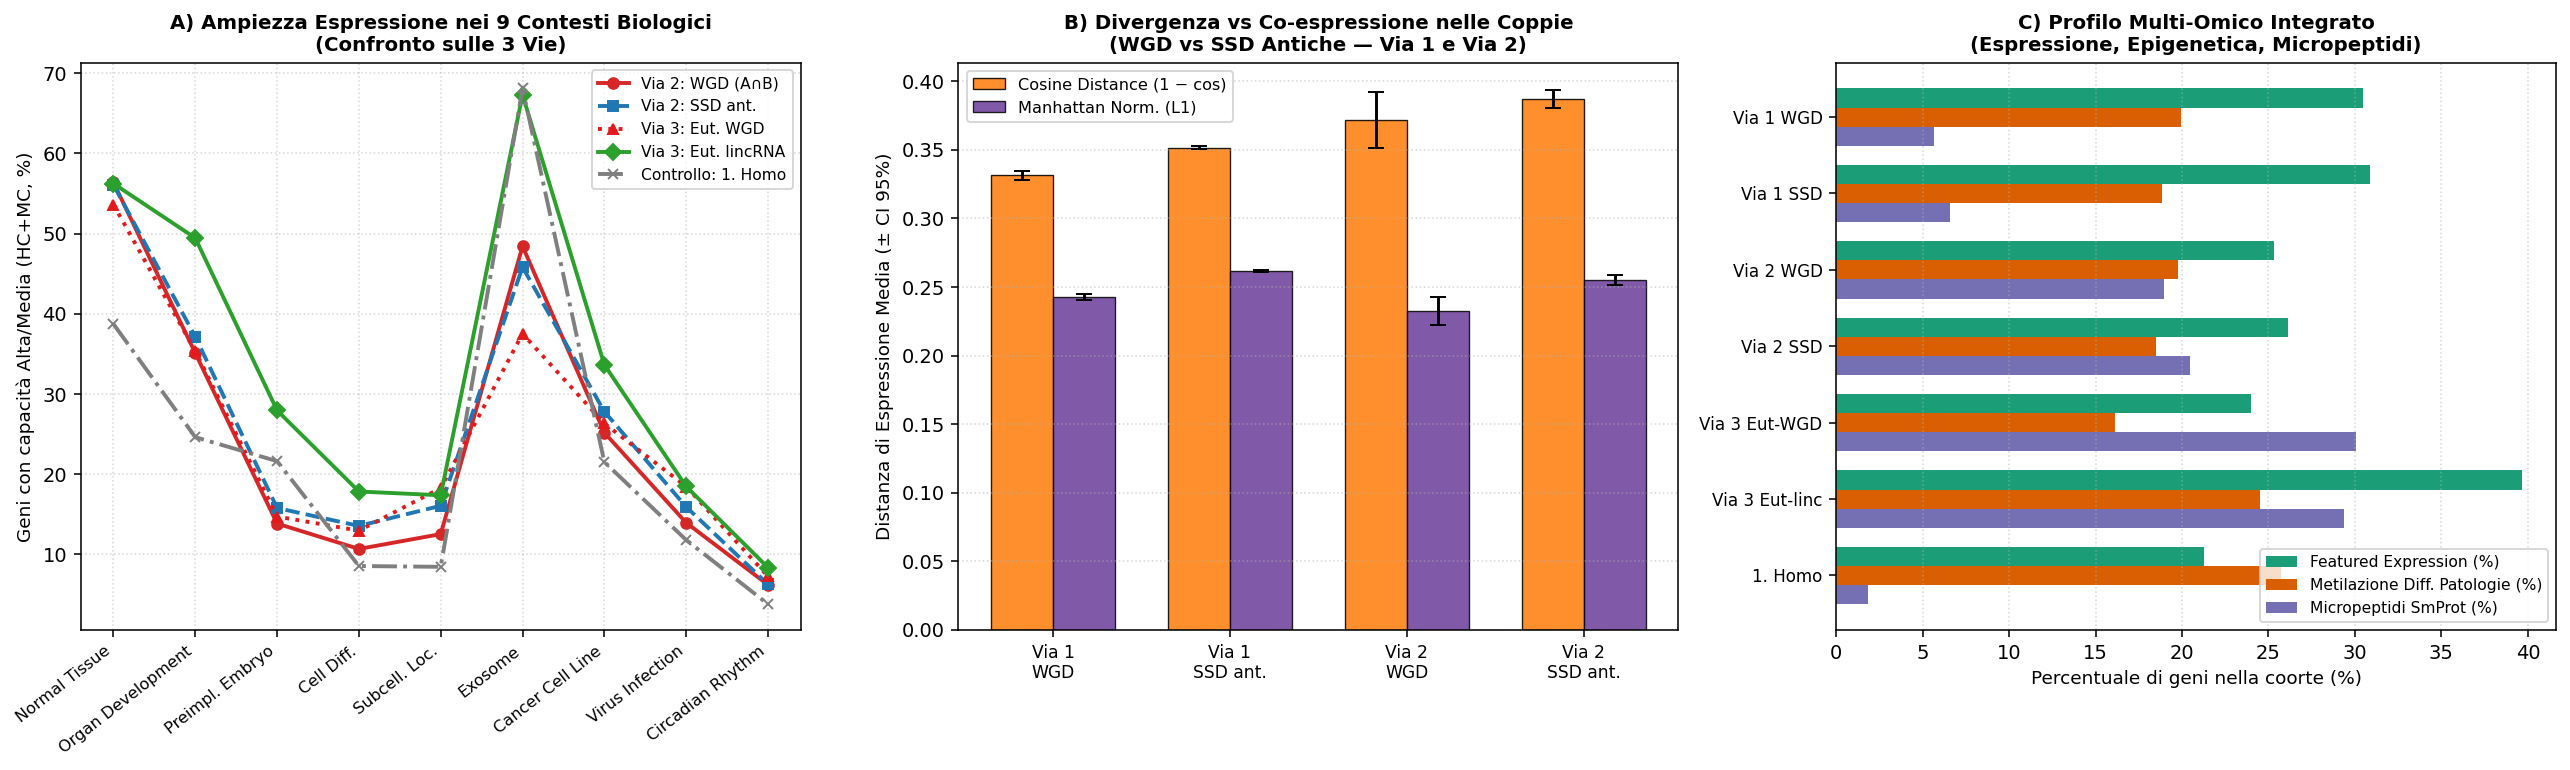

Figure Fase 4 salvate su Google Drive:
 - /content/rclone_drive/gold/phase4_expression_multiomics_summary.png
 - /content/rclone_drive/gold/phase4_expression_multiomics_summary.pdf


In [ ]:
png_p4, pdf_p4 = mo_analyzer.plot_phase4_summary(
    cohort_res=cohort_res,
    pair_res=pair_res,
    save_fig=True,
)
print(f"Figure Fase 4 salvate su Google Drive:\n - {png_p4}\n - {pdf_p4}")

## 6. Discussione dei Risultati della Fase 4

L'integrazione dei profili di espressione multi-contesto, della metilazione differenziale in 16 patologie e del catalogo sperimentale di micropeptidi (`SmProt`) sui **95.238 geni lncRNA canonici** di LncBook v2.0 (copertura del 100% nel database di espressione) produce quattro risultati principali che completano il quadro aperto nelle Fasi 2 e 3:

### 1. Co-espressione Conservata nelle Coppie WGD vs SSD Antiche (Via 1 e Via 2)
Mentre nella Fase 3 le coppie intrageniche WGD e SSD erano risultate indistinguibili nel layer *ceRNA* (miRNA), sul piano dell'espressione emerge una **differenza netta, coerente e statisticamente significativa in entrambe le vie e su tutte e quattro le metriche** (Cella 4, Pannello B):
* **Via 1 (Ramo A puro — 19.739 coppie WGD vs 220.057 SSD antiche):** le coppie WGD hanno una quota maggiore di coppie con entrambi i membri espressi (**85,60%** vs 83,32%), una **Cosine Distance ($1 - \cos$)** inferiore ($0{,}3314$ vs $0{,}3517$, Mann–Whitney $p = 1{,}83 \times 10^{-29}$), una **Manhattan normalizzata** inferiore ($0{,}2427$ vs $0{,}2616$, $p = 1{,}37 \times 10^{-80}$), minore asimmetria di espressione ($0{,}3957$ vs $0{,}4161$, $p = 3{,}03 \times 10^{-13}$) e maggiore concordanza esatta dei 9 contesti (**54,13%** vs 51,10%, $p = 1{,}73 \times 10^{-81}$).
* **Via 2 (Intersezione $A \cap B$, $\ge 15.\,\text{Amniota}$ — 762 coppie WGD vs 7.079 SSD antiche):** il segnale resiste integralmente anche sul subset ancestrale purificato: le coppie WGD sono espresse in coppia nel **72,97%** dei casi contro il **66,00%** delle SSD antiche (+7 punti percentuali), con distanze significativamente inferiori sia su **Cosine Distance** ($0{,}3718$ vs $0{,}3872$, MW $p = 0{,}0259$, KS $p = 0{,}0353$) sia su **Manhattan normalizzata** ($0{,}2326$ vs $0{,}2552$, MW $p = 4{,}92 \times 10^{-4}$, KS $p = 7{,}39 \times 10^{-4}$), minore asimmetria ($0{,}4434$ vs $0{,}4827$, $p = 0{,}0225$) e maggiore concordanza esatta (**55,63%** vs 53,08%, $p = 0{,}0038$).
* **Casi studio emblematici di due destini evolutivi opposti:** tra le coppie WGD Via 2 ad alta espressione e massima conservazione spiccano gli ohnologhi della fototrasduzione retinica **`PDE6B–PDE6C`** ($d_{\cos} = 0{,}095$, match 66,7%), le chinasi **`STK24–STK25`** ($d_{\cos} = 0{,}102$) e le galectine **`LGALS3–LGALS8`** ($d_{\cos} = 0{,}086$); all'estremo opposto ($d_{\cos} = 1{,}0$, completa subfunzionalizzazione di contesto) si collocano coppie WGD classiche con divergenza tissutale nota dei geni host, come i canali del sodio **`SCN8A–SCN4A`** (sistema nervoso vs muscolo scheletrico), i recettori **`ACVR2B–ACVR2A`** (entrambi al nodo `17. Euteleostomi`) e le stesse RBP ohnologhe **`CIRBP–ELAVL1`**.
* **Cautela metodologica (controllo futuro):** poiché questi lncRNA risiedono all'interno di geni host ohnologhi (notoriamente co-regolati per bilanciamento del dosaggio), sarà fondamentale disaccoppiare nella fase di raffinamento i lncRNA **`sense`** dagli **`antisense`**: se la minore distanza WGD vs SSD persiste anche sui soli `antisense`, è escluso che il fenomeno sia un mero artefatto di co-trascrizione (*read-through*) del gene host.

### 2. Via 3 (Ramo B): Dominanza Funzionale ed Epigenetica dei lincRNA Intergenici `17. Euteleostomi`
Esattamente come osservato sui network della Fase 3, anche sul piano dell'espressione e della metilazione i **633 lincRNA intergenici al nodo `17. Euteleostomi`** formano una classe nettamente distinta (Celle 2–3, Pannelli A e C):
* presentano il massimo tasso di **`Featured Expression`** (**39,65%** vs 23,97% in `Eut_WGD`, $p = 2{,}08 \times 10^{-8}$; vs 21,29% in `1. Homo`, $\text{OR} = 2{,}43$, $p = 2{,}63 \times 10^{-23}$) e il più alto score medio di espressione (**0,866** vs 0,654 in `Eut_WGD`, $p = 1{,}05 \times 10^{-11}$; vs 0,613 in `1. Homo`, $p = 1{,}24 \times 10^{-30}$);
* nel Pannello A la loro curva domina nettamente tutti i contesti dello sviluppo dei vertebrati: **`Organ Development`** al **49,45%** (contro 35,36% in `Eut_WGD` e 24,63% in `1. Homo`), **`Preimplantation Embryo`** al **27,96%** (vs 14,73%) e **`Cell Differentiation`** al **17,85%** (vs 8,56%);
* esibiscono la più alta incidenza di **metilazione differenziale al promotore** in patologie umane (**19,59%**, totale 24,49%) rispetto ai coevi intragenici `Eut_WGD` (10,02% promotore, totale 16,11%; $p = 5{,}48 \times 10^{-4}$).

All'interno degli intragenici al nodo `17. Euteleostomi`, i lncRNA ospitati in geni WGD mantengono comunque uno score espressivo significativamente superiore rispetto a quelli in altri geni host (`0,654` vs `0,590`, MW $p = 0{,}0329$).

### 3. Metilazione Differenziale in Patologia: Segnale Lieve in Via 1 e Caveat sul Controllo `1. Homo`
Nella Via 1 i lncRNA intragenici WGD mostrano una leggera ma significativa sovrarappresentazione di eventi di metilazione differenziale in patologia rispetto alle SSD antiche (19,97% vs 18,87%, $\text{OR} = 1{,}073$, $p = 0{,}0196$; promotore 11,94% vs 10,84%), in direzione coerente con l'ipotesi di Makino & McLysaght (2010), sebbene l'effetto non raggiunga significatività nella Via 2 per minore numerosità (19,74% vs 18,50%, $p = 0{,}41$). Va inoltre notato che il controllo `1. Homo` presenta un'alta frazione di metilazione differenziale (25,73%), plausibilmente legata alla sovrapposizione con isole CpG/elementi ripetuti e alla copertura delle sonde degli array di metilazione; questo suggerisce cautela nell'interpretare la metilazione globale senza normalizzazione per densità di sonde CpG.

### 4. Scoperta Critica sui Micropeptidi (`SmProt`): Gradiente Evolutivo Estremo e Controllo di Qualità
L'analisi di `lncbook_sprotein.parquet` rivela un fortissimo gradiente con l'età filostratigrafica (Cella 2, Pannello C): la frazione di lncRNA associati a piccoli peptidi (`SmProt`, prevalentemente da Ribo-seq; validati in spettrometria di massa solo tra 0,15% e 1,58%) sale dal **1,83%** in `1. Homo` e **3,38%** in `12. Eutheria` al **18,97–20,46%** nella Via 2 ($\ge 15.\,\text{Amniota}$) fino al **29,38–36,82%** al nodo `17. Euteleostomi` (`Eut_lincRNA` vs `1. Homo`: $\text{OR} = 22{,}38$, **$p = 9{,}40 \times 10^{-127}$**; `Eut_WGD` vs `12. Eutheria`: $\text{OR} = 12{,}28$, **$p = 1{,}04 \times 10^{-93}$**).

Due implicazioni rilevanti emergono da questo dato:
1. **Deplezione relativa nei WGD rispetto agli altri host:** sia nella Via 1 (5,66% vs 6,57%, $\text{OR} = 0{,}852$, $p = 0{,}0015$) sia tra gli intragenici `17. Euteleostomi` (`Eut_WGD` 30,06% vs `Eut_other` 36,82%, $\text{OR} = 0{,}737$, $p = 0{,}0104$), i lncRNA associati a host WGD sono *meno* arricchiti di micropeptidi rispetto ai controlli, suggerendo che la loro ritenzione in host WGD non è spiegata da potenziale codificante nascosto.
2. **Controllo di sensibilità necessario:** l'enorme arricchimento di `SmProt` nei nodi più antichi indica che la conservazione di sequenza usata da LncBook v2.0 intercetta preferenzialmente trascritti bifunzionali o contenenti piccoli ORF tradotti (sORF); ripetere i test chiave delle Fasi 2–4 escludendo `has_sprotein == True` fornirà una verifica definitiva sui lncRNA *strettamente non codificanti*.

## 7. Conclusioni

La Fase 4 completa il percorso analitico di base delle Fasi 1–4 dimostrando che l'impronta delle 1R/2R-WGD nei lncRNA umani si manifesta con un profilo **nettamente distinto da quello dei microRNA**, articolato su tre livelli complementari:

1. **Ritenzione di co-espressione nelle coppie intrageniche WGD (Via 1 e Via 2):** pur avendo perso la ridondanza di legame ai miRNA (Fase 3), le coppie di lncRNA ospitate in geni ohnologhi (WGD) mantengono una co-espressione significativamente più elevata e più simmetrica rispetto alle coppie SSD antiche in tutti gli indicatori testati (Via 2: Cosine Distance $p = 0{,}026$, Manhattan $p = 4{,}9 \times 10^{-4}$, Asimmetria $p = 0{,}022$, Exact Match $p = 0{,}0038$), con casi paradigmatici sia di co-espressione conservata (`PDE6B–PDE6C`, `STK24–STK25`) sia di subfunzionalizzazione completa (`SCN8A–SCN4A`, `ACVR2B–ACVR2A`).
2. **Centralità regolatoria ed evolutiva dei lincRNA intergenici `17. Euteleostomi` (Via 3):** i 633 lincRNA intergenici ancestrali dominano in modo convergente l'espressione nei contesti di sviluppo (`Organ Development` 49,45%), la `Featured Expression` (39,65%, $p = 2{,}6 \times 10^{-23}$ vs `1. Homo`) e la metilazione differenziale al promotore (19,59%), saldandosi con la loro superiorità topologica già emersa nella Fase 3.
3. **Rigore sul potenziale codificante nascosto (`SmProt`):** circa il 30% dei lncRNA al nodo `17. Euteleostomi` porta annotazioni Ribo-seq di micropeptidi (contro l'1,8% in `1. Homo`), ma i lncRNA in host WGD risultano *relativamente meno* codificanti dei controlli non-WGD ($p = 0{,}010$), confermando la natura genuinamente non codificante del segnale WGD.

## 8. Prossimi Sviluppi della Ricerca

I risultati ottenuti nelle Fasi 1–4 delineano una prima caratterizzazione quantitativa dell'impronta delle duplicazioni 1R/2R-WGD nei lncRNA umani e aprono due direzioni di approfondimento diretto:

1. **Controlli di sensibilità e disaccoppiamento meccanicistico:**
   * **Separazione `sense` vs `antisense` sulla co-espressione:** verificare se la minore distanza di espressione delle coppie intrageniche WGD rispetto alle SSD antiche persiste anche sulle sole coppie `antisense` (a promotore indipendente), escludendo un eventuale contributo di co-trascrizione (*read-through*) del gene host.
   * **Controllo di indipendenza a livello di coppia host:** replicare i test delle Fasi 3 e 4 aggregando un solo valore per coppia di geni host (e sul sottoinsieme 1:1 puro di 101 coppie WGD) per rimuovere ogni effetto di annidamento di più lncRNA nello stesso host.
   * **Verifica di purezza non codificante (`SmProt`):** ripetere la curva $A \cap B$ (Fase 2) e i confronti espressivi (Fase 4) escludendo i trascritti con annotazioni Ribo-seq/spettrometria di massa in `SmProt`, per separare i lncRNA strettamente non codificanti da eventuali trascritti bifunzionali.
   * **Omologia di sequenza e sintenia dei lincRNA intergenici:** valutare la presenza di micro-omologia di sequenza tra i membri delle coppie WGD Via 2 tramite il trascrittoma FASTA di LncBook v2.0 e analizzare quanti dei 635 lincRNA intergenici `17. Euteleostomi` ricadono all'interno di blocchi sintenici ohnologhi (*ohnoblocks*).

2. **Estensioni su sorgenti sperimentali ortogonali:**
   * **Layer fisico lncRNA–RBP ad alta copertura:** integrare database CLIP-seq complementari (es. ENCORI/starBase o NPInter v5) per aumentare la copertura sui lncRNA intragenici e rendere statisticamente testabili i **PPI-Bifans** sulle coppie WGD e SSD delle Vie 1 e 2.
   * **Profili quantitativi continui e *single-cell*:** affiancare alla matrice meta-categoriale di LncBook v2.0 profili continui TPM multi-tessuto e a singola cellula (LncExpDB e NONCODE v7), per stimare l'indice di specificità tissutale $\tau$ e confrontare direttamente la co-espressione dei lncRNA con quella dei rispettivi geni host.
   * **Arricchimento funzionale (GO/Pathway):** caratterizzare le vie biologiche associate ai 368 geni host WGD che ospitano coppie di lncRNA nella Via 2 ($A \cap B$).